# Gold XANES standard mixture
## Problem
Recover known-standard spectral weights and the measured sample's modeled Au-L3 spectrum. This is a calibrated-library inverse problem, not unknown-endmember factorization. There is no independent composition ground truth: native outputs below are standard-method references. Chemical attribution is limited by overlapping standards and pH/hydration mismatch. Exact time and concentration are not identified in this export; no kinetic inference is made.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if not (ROOT/'src').is_dir():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.main import reconstruct
from src.preprocessing import load_data
from src.solvers import MODELS,fit_model
from src.visualization import comparisons,ambiguity,LABELS
raw=load_data(ROOT/'data/raw_data.npz')
upstream=dict(np.load(ROOT/'notebooks/reference_outputs/upstream_comparisons.npz'))


## Data
All original327sample measurements and the six full, independently measured standard spectra are bundled. They were exported from the author's cyanobacteria project, already normalized and energy aligned using a gold foil. The associated experiment exposed cyanobacteria to gold chloride in a Teflon cell and repeatedly measured synchrotron absorption. Published study temperature was25°C. The benchmark uses the native inclusive floor-index interval11870–12030eV:160points at11869.660–12029.756eV. All standards cover this interval; no extrapolation or artificial mixture is needed.

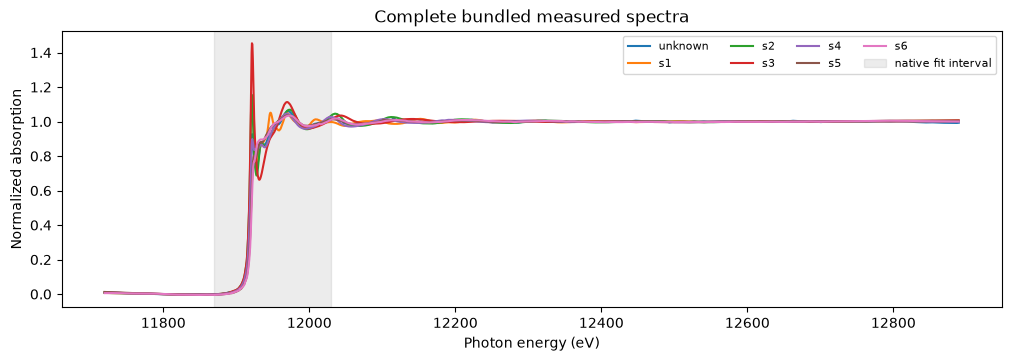

{'unknown': (1, 327, 2), 's1': (1, 327, 2), 's2': (1, 327, 2), 's3': (1, 308, 2), 's4': (1, 327, 2), 's5': (1, 327, 2), 's6': (1, 324, 2)}


In [2]:
fig,ax=plt.subplots(figsize=(10,3.5),layout='constrained')
for name in raw:
    a=raw[name][0];ax.plot(a[:,0],a[:,1],label=name)
ax.axvspan(11869.66,12029.756,color='grey',alpha=.15,label='native fit interval')
ax.set(xlabel='Photon energy (eV)',ylabel='Normalized absorption',title='Complete bundled measured spectra')
ax.legend(ncol=4,fontsize=8);plt.show()
print({k:v.shape for k,v in raw.items()})

## Physics
The linear-combination model is
$$f_i=\sum_{j=1}^{6} w_j S_j(E_i),\qquad w_j\geq0,\quad\sum_jw_j=1.$$
$E_i$ is energy in eV; $S_j$ is normalized measured standard absorption; $w_j$ is a dimensionless spectral weight; $f_i$ is modeled absorption. The residual $\mu_i-f_i$ includes noise and library mismatch. The source paper explicitly notes that hydroxide can compensate hydration/pH differences rather than prove that compound exists in the sample. Similar sulfur complexes likewise weaken unique attribution. A fit coefficient is not an independently measured mass fraction.

## Method
Actively run all eleven native subsets: metal/chloride plus zero, one or two other standards. Native finite-bound coordinates are $w=(1+\sin u)/2$; the dependent last weight is $1-\sum w$ clipped to[0,1]. That upstream clipping can violate a simplex outside the physical region; the selected result is independently checked. Local code preserves sequential arithmetic, initialization and MINPACK finite-difference Levenberg–Marquardt settings. The objective is $\chi^2=\sum_i[(\mu_i-f_i)/0.001]^2$;0.001 is an assumed uniform scale, not measured noise. Rank by $\chi^2/(160-k)$ for $k$ independent weights. AIC and BIC are also computed. No regularization or energy-shift optimization is used.

In [3]:
started=time.perf_counter()
energy,observation,standards,result=reconstruct(ROOT/'data/raw_data.npz')
seconds=time.perf_counter()-started
best=result['best']
np.savez(ROOT/'output/reconstruction.npz',weights=result['weights'][best:best+1],reconstruction=result['fits'][best:best+1])
spec=importlib.util.spec_from_file_location('judge_review',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(ROOT/'output/reconstruction.npz')
assert report['passed'],report
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
print('Fresh full eleven-model runtime (seconds):',seconds)
print(json.dumps(report,indent=2))
assert np.all(result['weights'][best]>=0) and abs(result['weights'][best].sum()-1)<1e-12


Fresh full eleven-model runtime (seconds): 0.006793000036850572
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "weight_max": 0.0,
    "spectral_rmse": 0.0,
    "forward_rmse": 5.962248466967893e-17,
    "observation_rmse": 0.003618693081344629,
    "simplex_error": 0.0
  },
  "thresholds": {
    "weight_max": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "spectral_rmse": {
      "comparison": "<=",
      "boundary": 1e-05
    },
    "forward_rmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "observation_rmse": {
      "comparison": "<=",
      "boundary": 0.0037
    },
    "simplex_error": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


## Results
Every solid reconstruction below is freshly computed. Native references are loaded solely for comparison and are never labeled truth. The two- and three-standard fits expose structured residuals, while the selected four-standard fit reduces their amplitude. The table retains every original comparison; changes in sulfur weights across acceptable models illustrate model dependence.

| Model | Standards | Fresh reduced chi² | Native reduced chi² | Fresh AIC | Fresh BIC |
|---|---|---|---|---|---|
|1|1,2|58.736295|58.736295|652.686119|655.761292|
|2|1,2,3|40.179625|40.179625|592.925001|599.075348|
|3|1,2,4|37.193215|37.193215|580.567613|586.717961|
|4|1,2,5|32.141092|32.141092|557.209051|563.359398|
|5|1,2,6|37.200736|37.200736|580.599964|586.750312|
|6|1,2,3,4|28.133581|28.133581|536.885743|546.111265|
|7|1,2,3,5|14.726890|14.726890|433.319525|442.545047|
|8|1,2,3,6|13.345161|13.345161|417.556139|426.781660|
|9|1,2,4,5|30.127380|30.127380|547.841024|557.066545|
|10|1,2,5,6|32.353742|32.353742|559.248270|568.473792|
|11|1,2,4,6|34.347148|34.347148|568.814558|578.040080|

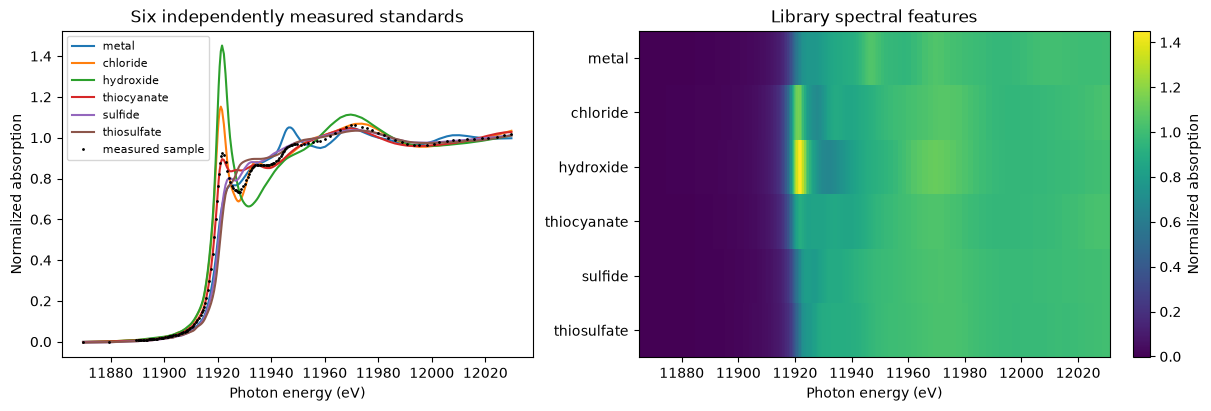

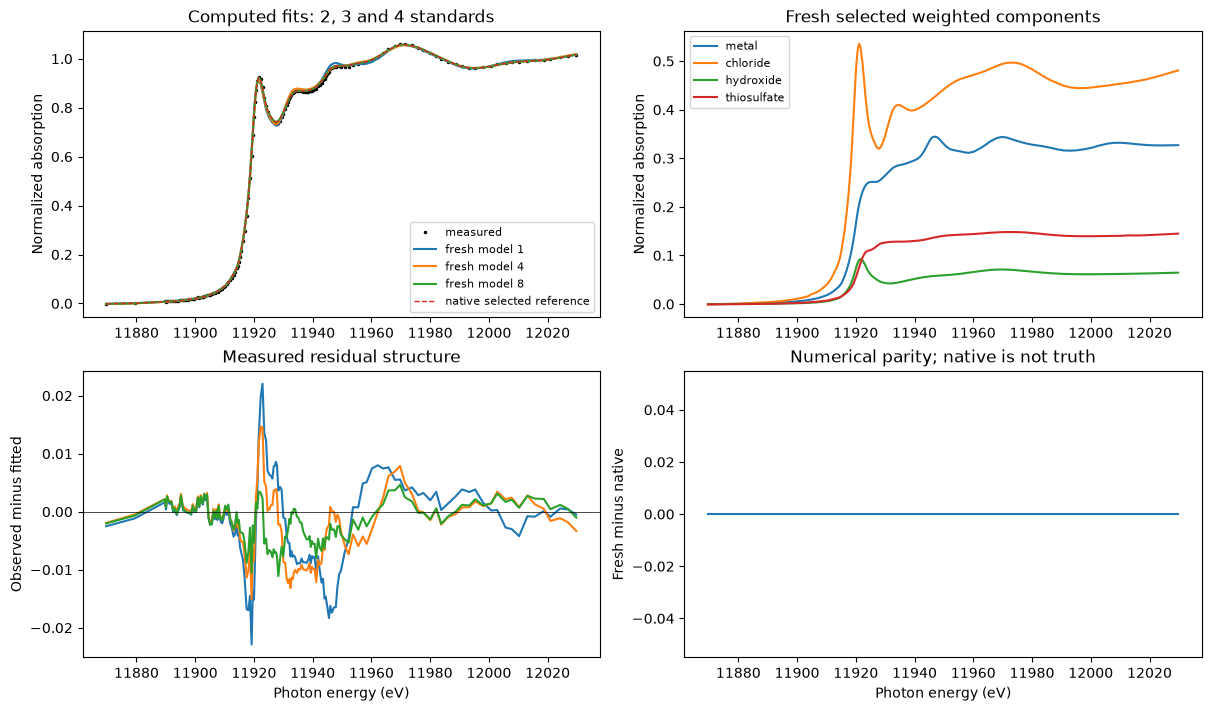

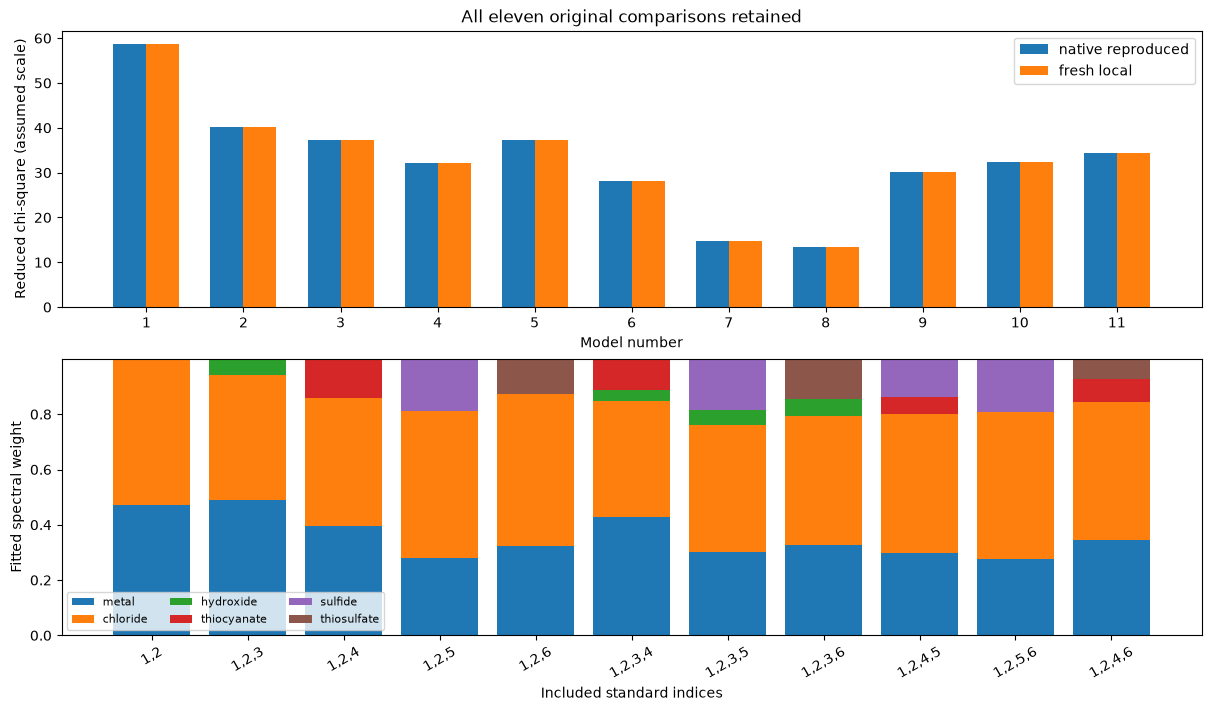

Maximum native weight and spectral differences: 0.0 0.0


In [4]:
lines=['| Model | Standards | Fresh reduced chi² | Native reduced chi² | Fresh AIC | Fresh BIC |','|---|---|---|---|---|---|']
for i,m in enumerate(MODELS):
    s=result['statistics'][i];u=upstream['statistics'][i]
    lines.append(f"|{i+1}|{','.join(str(k+1) for k in m)}|{s[1]:.6f}|{u[1]:.6f}|{s[2]:.6f}|{s[3]:.6f}|")
display(Markdown('\n'.join(lines)))
for fig in comparisons(energy,observation,standards,result,upstream):display(fig);plt.close(fig)
print('Maximum native weight and spectral differences:',np.max(abs(result['weights']-upstream['weights'])),np.max(abs(result['fits']-upstream['fits'])))


The next comparisons examine ambiguity, not just numerical parity. Correlation is Pearson correlation here (not an evaluation NCC). Singular values describe the affine mixture design. The ±0.2eV standard shifts are explicitly synthetic calibration-sensitivity experiments, rerun across all eleven models; the bound benchmark remains the original aligned observation. Endpoint interpolation is held at the nearest value in this supplementary test.

Finally, an unconstrained six-standard affine fit is computed as a diagnostic. It can improve residuals by introducing negative weights; it is not substituted for a physical mixture or presented as an additional successful reconstruction.

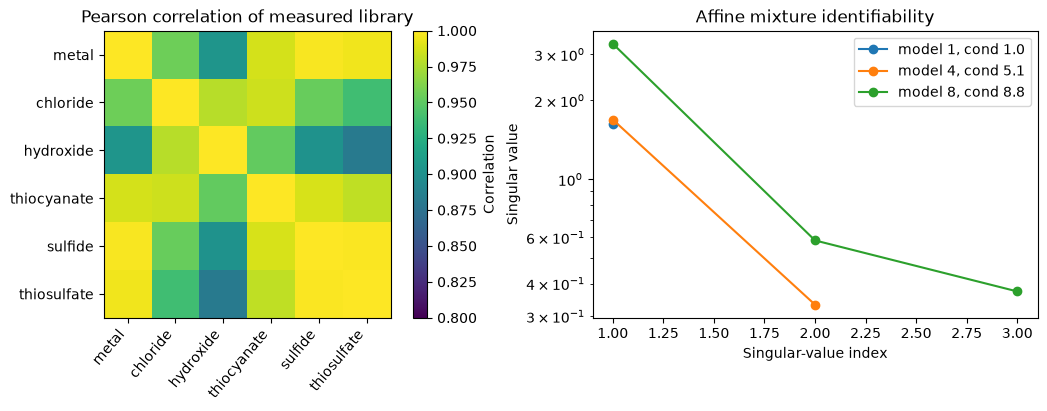

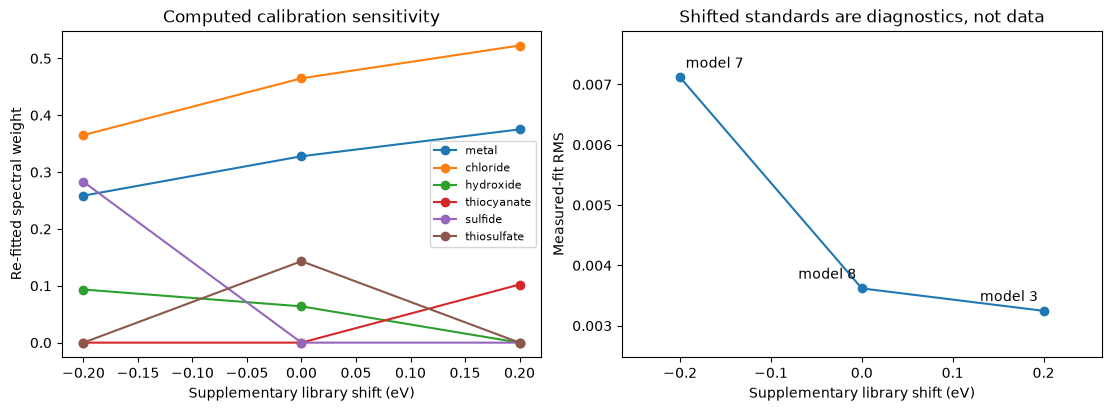

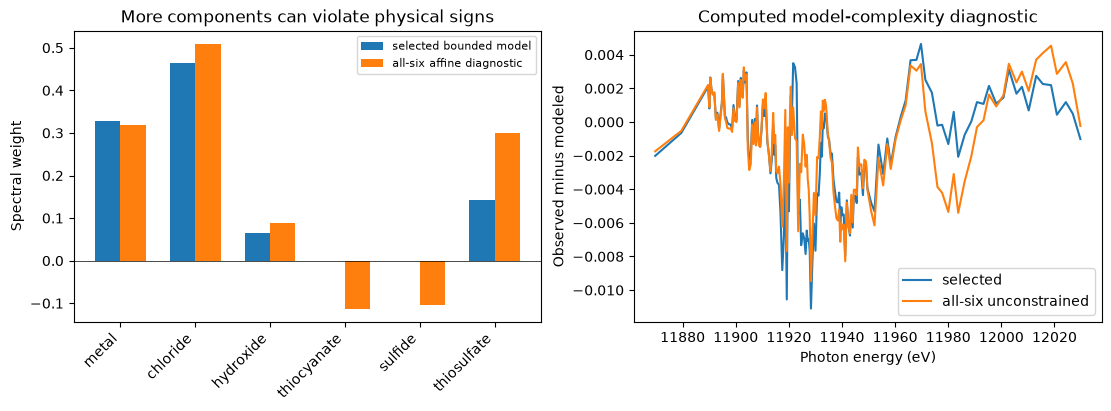

Selected spectral weights: {'metal': np.float64(0.32788267007268657), 'chloride': np.float64(0.4650128453960943), 'hydroxide': np.float64(0.06383803169830504), 'thiocyanate': np.float64(0.0), 'sulfide': np.float64(0.0), 'thiosulfate': np.float64(0.14326645283291412)}
All-six diagnostic weights: [ 0.31867117  0.5091106   0.08817272 -0.11237593 -0.10331691  0.29973834]


In [5]:
for fig in ambiguity(energy,observation,standards,result):display(fig);plt.close(fig)
free=np.linalg.lstsq((standards[:5]-standards[5]).T,observation-standards[5],rcond=None)[0]
unconstrained=np.r_[free,1-free.sum()]
fig,ax=plt.subplots(1,2,figsize=(11,4),layout='constrained')
x=np.arange(6);ax[0].bar(x-.17,result['weights'][best],.34,label='selected bounded model');ax[0].bar(x+.17,unconstrained,.34,label='all-six affine diagnostic')
ax[0].axhline(0,color='black',lw=.5);ax[0].set_xticks(x,LABELS,rotation=45,ha='right');ax[0].set(ylabel='Spectral weight',title='More components can violate physical signs');ax[0].legend(fontsize=8)
ax[1].plot(energy,observation-result['fits'][best],label='selected');ax[1].plot(energy,observation-unconstrained@standards,label='all-six unconstrained')
ax[1].legend();ax[1].set(xlabel='Photon energy (eV)',ylabel='Observed minus modeled',title='Computed model-complexity diagnostic');plt.show()
print('Selected spectral weights:',dict(zip(LABELS,result['weights'][best])))
print('All-six diagnostic weights:',unconstrained)


## Conclusion
The complete measured observation and six-standard library yield a reproducible four-standard spectral mixture. Fresh reconstruction agrees with the independently run native method and passes separate forward-consistency and measured-residual checks. The eleven-model comparison, affine diagnostic and calibration perturbations show why a low residual alone does not establish unique chemical speciation. No independent ground truth, measured noise model, reaction time or absolute mass fractions are invented. The source paper's chemical interpretation remains broader than a numerical library match.